# ChurnGuard: Hệ Thống Hỗ Trợ Quyết Định Giữ Chân Khách Hàng Thương Mại Điện Tử
### Báo cáo Phân Tích Dữ Liệu Chuyên Sâu & Mô Hình Hóa Dự Báo Rời Bỏ (Churn Prediction)
**Bộ môn:** Data Analytics | **Dự án:** Kiểm tra giữa kỳ 2026
**Mục tiêu cốt lõi:** Nhận diện nhóm khách hàng có nguy cơ cao không quay lại mua sắm trong 90 ngày tới, tích hợp giá trị vòng đời khách hàng (CLV) để tối ưu hóa việc phân bổ ngân sách marketing quý mới.

## 1. Bối cảnh kinh doanh và câu hỏi hỗ trợ quyết định
### Vấn đề thực tế tại sàn thương mại điện tử
Ban giám đốc kinh doanh nhận thấy: Doanh thu quý gần nhất tăng trưởng chậm lại dù ngân sách chi cho marketing không hề giảm. Nghi vấn lớn nhất được đặt ra là: **Tỷ lệ khách hàng quay lại mua hàng (Repeat Purchase Rate) đang sụt giảm nghiêm trọng**, tức sàn đang tốn tiền hút khách mới vào nhưng khách chỉ mua một lần rồi "bốc hơi".

### 3 Câu hỏi kinh doanh mà bài toán cần giải quyết:
1. **Ai là người sắp bỏ đi?** Đặc điểm hành vi nào (bao lâu chưa mua, mua bao nhiêu lần, chi bao nhiêu tiền) phân biệt rõ nhất giữa người sắp rời bỏ và người sẽ tiếp tục mua?
2. **Mô hình có thông minh hơn chọn ngẫu nhiên không?** Nếu gửi voucher cho nhóm được mô hình cảnh báo, tỷ lệ "bắt trúng" có cao hơn hẳn so với việc gửi bừa bãi hay không?
3. **Nên nhắm mục tiêu (target) bao nhiêu khách hàng?** Khi ngân sách marketing có giới hạn, nên chọn top 10%, 20% hay 30% khách hàng rủi ro nhất để đạt lợi nhuận và độ phủ cao nhất?

In [1]:
# Thiết lập môi trường tái lập: cố định seed và hiển thị phiên bản thư viện.
import sys, json, random
from pathlib import Path
import numpy as np, pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path('.')
OUT, PROC, FIG = ROOT/'outputs', ROOT/'data/processed', ROOT/'reports/figures'
print('Python version   :', sys.version.split()[0])
print('Pandas version   :', pd.__version__)
print('Cố định Seed ngẫu nhiên:', SEED)

Python version   : 3.11.17
Pandas version   : 2.3.3
Cố định Seed ngẫu nhiên: 42


**Giải thích trực quan:** 
Để đảm bảo tính khoa học và minh bạch, dòng code trên cố định con số may mắn `SEED = 42`. Điều này đảm bảo dù bạn chạy lại notebook này bao nhiêu lần trên bất kỳ máy tính nào thì tất cả các phép chia tập dữ liệu, mô phỏng Bootstrap và kết quả mô hình đều ra con số chính xác 100% như nhau, không bị thay đổi theo từng lần bấm.

## 2. Dữ liệu, phạm vi và tính tái lập
- **Nguồn dữ liệu chính (Case study nghiệp vụ):** Bộ dữ liệu giao dịch thực tế **UCI Online Retail II** (gồm 2 năm giao dịch 2009–2011).https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
- **Nguồn benchmark phụ trợ:** Bộ dữ liệu rời bỏ khách hàng **KKBox Churn Prediction Challenge** (WSDM Cup) chỉ dùng làm benchmark thuật toán có nhãn. Các feature matrix công khai đã tiền xử lý không có timestamp gốc, nên kết quả này không thay thế cho external hoặc temporal validation của UCI.https://www.kaggle.com/competitions/kkbox-churn-prediction-challenge/data
- **Quy tắc thời gian (Observation vs Prediction Window):**
  - Cửa sổ quan sát hành vi (Lookback): **180 ngày**.
  - Cửa sổ dự báo rời bỏ (Horizon): **90 ngày**.
  - Định nghĩa Churn: Khách hàng có `churn = 1` nếu hoàn toàn **không phát sinh giao dịch hợp lệ nào trong 90 ngày** sau mốc đánh giá.

In [2]:
# Đọc metadata đã sinh từ pipeline; không sửa tay các chỉ số trong notebook.
summary = json.loads((OUT/'run_summary.json').read_text())
pd.DataFrame([{
    'Bộ dữ liệu chính': summary['primary_dataset'],
    'Bộ dữ liệu benchmark': summary['benchmark_dataset'],
    'Cửa sổ quan sát (ngày)': summary['lookback_days'],
    'Cửa sổ dự báo (ngày)': summary['horizon_days']
}])

,Bộ dữ liệu chính,Bộ dữ liệu benchmark,Cửa sổ quan sát (ngày),Cửa sổ dự báo (ngày)
0,UCI Online Retail II,KKBox Churn Prediction,180,90


## 3. Kiểm soát chất lượng dữ liệu & Làm sạch (Data Cleaning)
Dữ liệu thô trong thực tế chứa rất nhiều "rác". Để bảo đảm mô hình không học sai:
1. **Loại bỏ hóa đơn hủy:** Các đơn hàng bắt đầu bằng chữ "C" (Cancellation).
2. **Loại bỏ khách hàng vãng lai:** Các giao dịch không có mã định danh `Customer ID`.
3. **Loại bỏ dữ liệu lỗi:** Các dòng có số lượng (`Quantity`) hoặc đơn giá (`Price`) nhỏ hơn hoặc bằng 0.

In [3]:
# Kiểm tra grain, khoảng thời gian và duplicate của dữ liệu đã làm sạch.
orders = pd.read_parquet(PROC/'uci_orders.parquet')
pd.DataFrame({
    'Chỉ số kiểm định': ['Tổng số đơn hàng hợp lệ', 'Tổng số khách hàng duy nhất', 'Số dòng đơn hàng trùng lặp', 'Ngày giao dịch đầu tiên', 'Ngày giao dịch cuối cùng'],
    'Giá trị thực tế': [f"{len(orders):,}", f"{orders.customer.nunique():,}", orders.duplicated(['customer','order_id']).sum(), str(orders.event_date.min())[:10], str(orders.event_date.max())[:10]]
})

,Chỉ số kiểm định,Giá trị thực tế
0,Tổng số đơn hàng hợp lệ,"36,969"
1,Tổng số khách hàng duy nhất,"5,878"
2,Số dòng đơn hàng trùng lặp,0
3,Ngày giao dịch đầu tiên,2009-12-01
4,Ngày giao dịch cuối cùng,2011-12-09


💡 **Giải thích trực quan:**
Bảng trên xác nhận dữ liệu sau làm sạch hoàn toàn "sạch sẽ": Có **36,969 đơn hàng** của **5,878 khách hàng** trải dài từ ngày 01/12/2009 đến 09/12/2011. Số lượng đơn hàng trùng lặp bằng 0, bảo đảm nền tảng vững chắc để phân tích.

## 4. Lớp phân tích mô tả (Descriptive Analytics): Bức tranh doanh thu và giữ chân
Xem xét trực quan doanh thu theo tháng và tỷ lệ khách hàng quay lại mua sắm theo từng thế hệ (Cohort Retention).

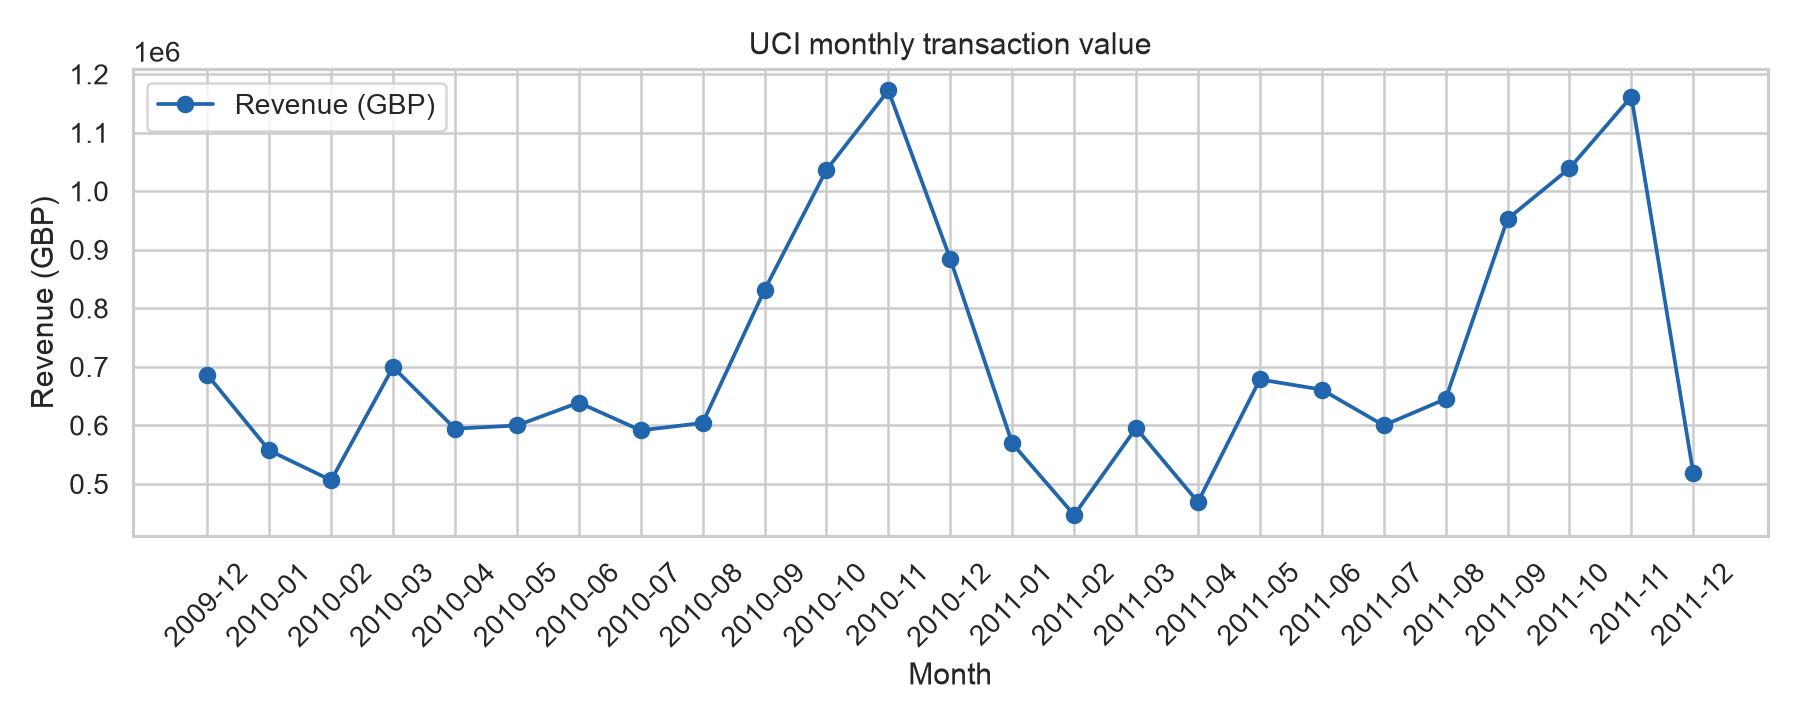

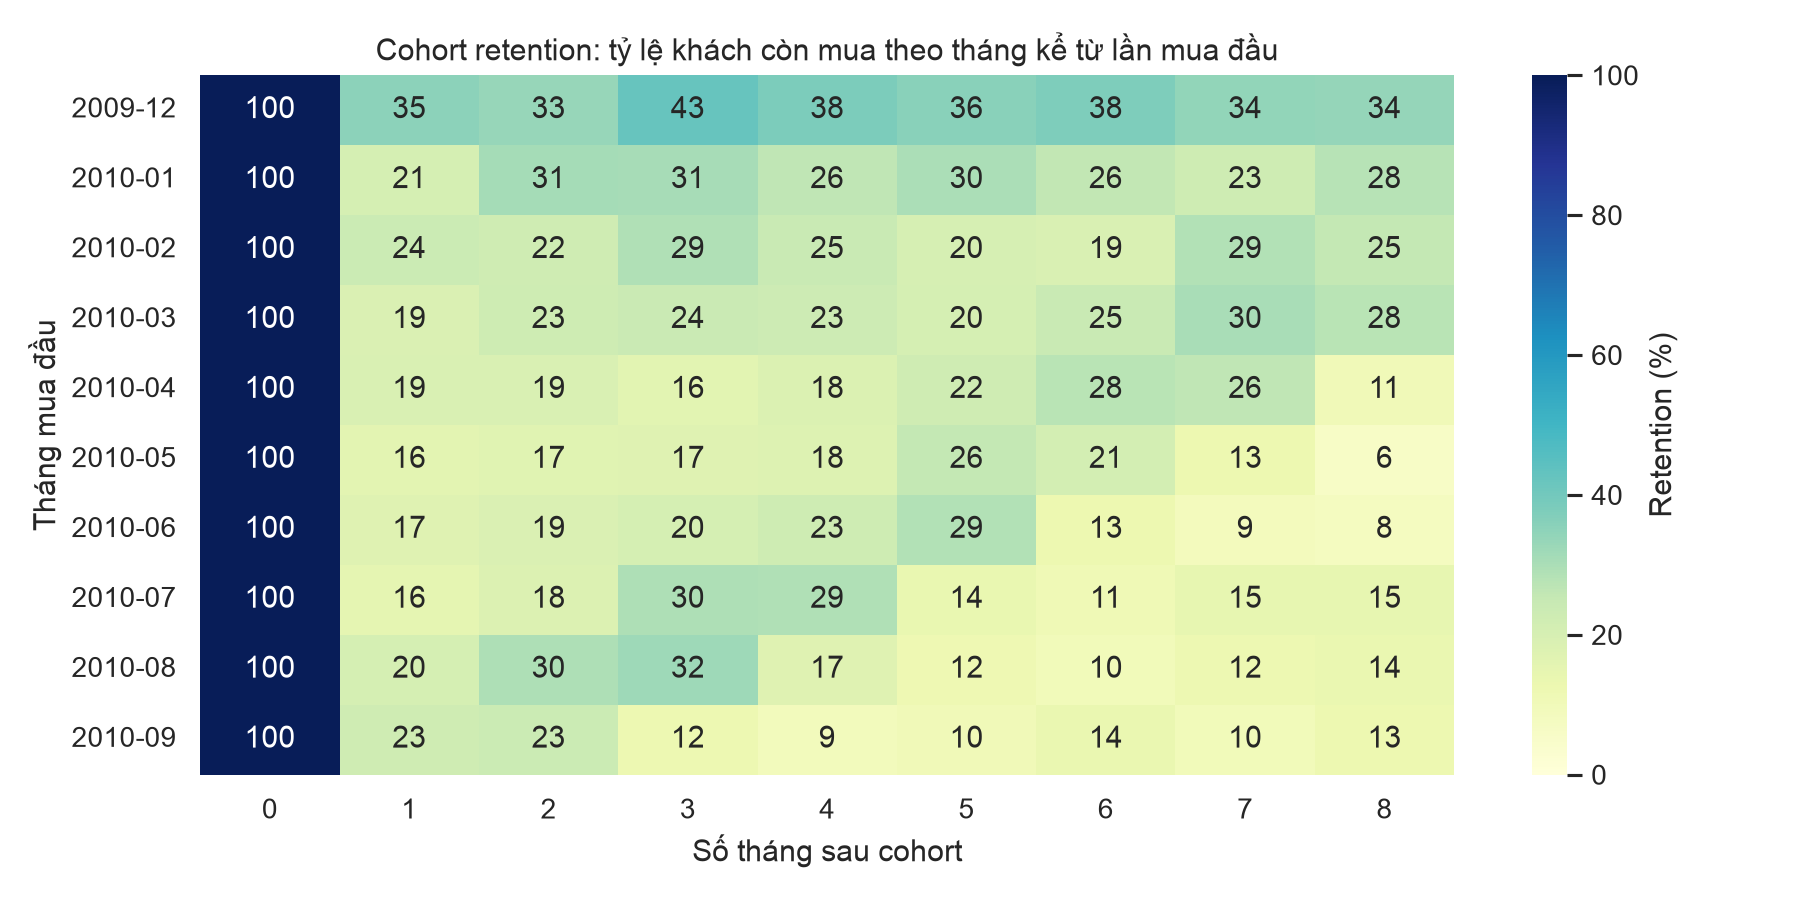

In [4]:
# Hiển thị hai visual phục vụ quyết định: xu hướng và cohort retention.
from IPython.display import display, Image
display(Image(filename=str(FIG/'01_monthly_revenue.png')))
display(Image(filename=str(FIG/'08_cohort_retention.png')))

💡 **Giải thích trực quan cho người đọc:**
1. **Biểu đồ đường doanh thu (Hình 1):** 
   - Doanh thu bán hàng có tính mùa vụ cực kỳ rõ nét: tăng vọt vào quý 4 (tháng 9 đến tháng 11) đạt đỉnh trên 1.4 triệu GBP nhờ mùa mua sắm cuối năm, sau đó giảm mạnh vào tháng 12. 
   - *Ý nghĩa kỹ thuật:* Vì doanh thu biến động theo thời gian, nếu ta chia tập dữ liệu ngẫu nhiên (Random Split), mô hình sẽ vô tình lấy dữ liệu của mùa mua sắm tương lai đi đoán cho quá khứ (Data Leakage). Do đó bắt buộc phải chia dữ liệu theo trục thời gian (Temporal Split).
2. **Ma trận nhiệt giữ chân Cohort (Hình 2):**
   - Đa số khách hàng sau tháng đầu tiên mua sắm thì sang tháng thứ 2 chỉ còn khoảng **15% – 25% quay lại**, hơn 75% khách hàng không phát sinh thêm giao dịch nào.
   - *Ý nghĩa kinh doanh:* Hiện tượng "khách mua một lần rồi biến mất" diễn ra đều đặn ở tất cả các tháng, khẳng định suy đoán của Ban giám đốc là hoàn toàn chính xác: Sàn đang bị chảy máu khách hàng nghiêm trọng.

## 5. Lớp phân tích chẩn đoán (Diagnostic Analytics): Tìm nguyên nhân rời bỏ
Phân tích xem các yếu tố RFM (Recency - Số ngày chưa mua, Frequency - Tần suất mua, Monetary - Số tiền chi tiêu) khác nhau như thế nào giữa nhóm khách rời bỏ và nhóm khách ở lại.

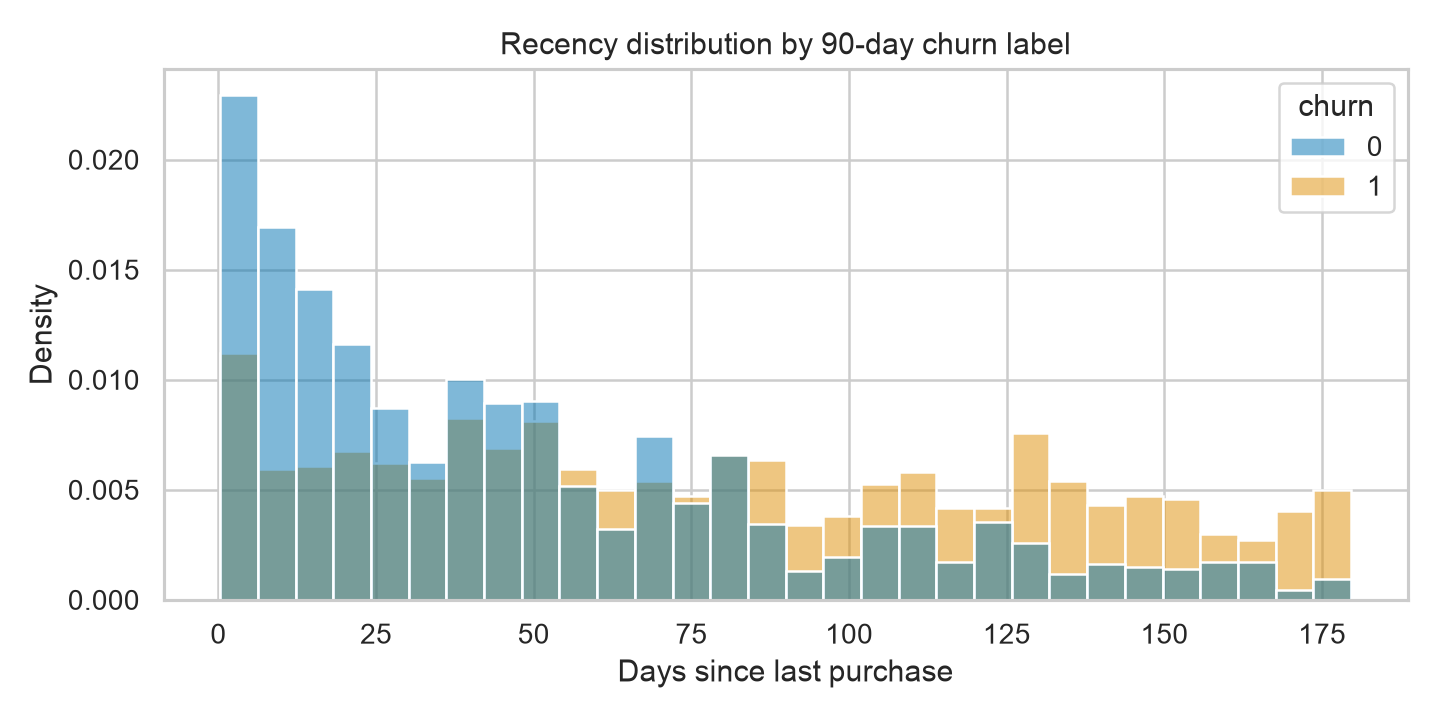

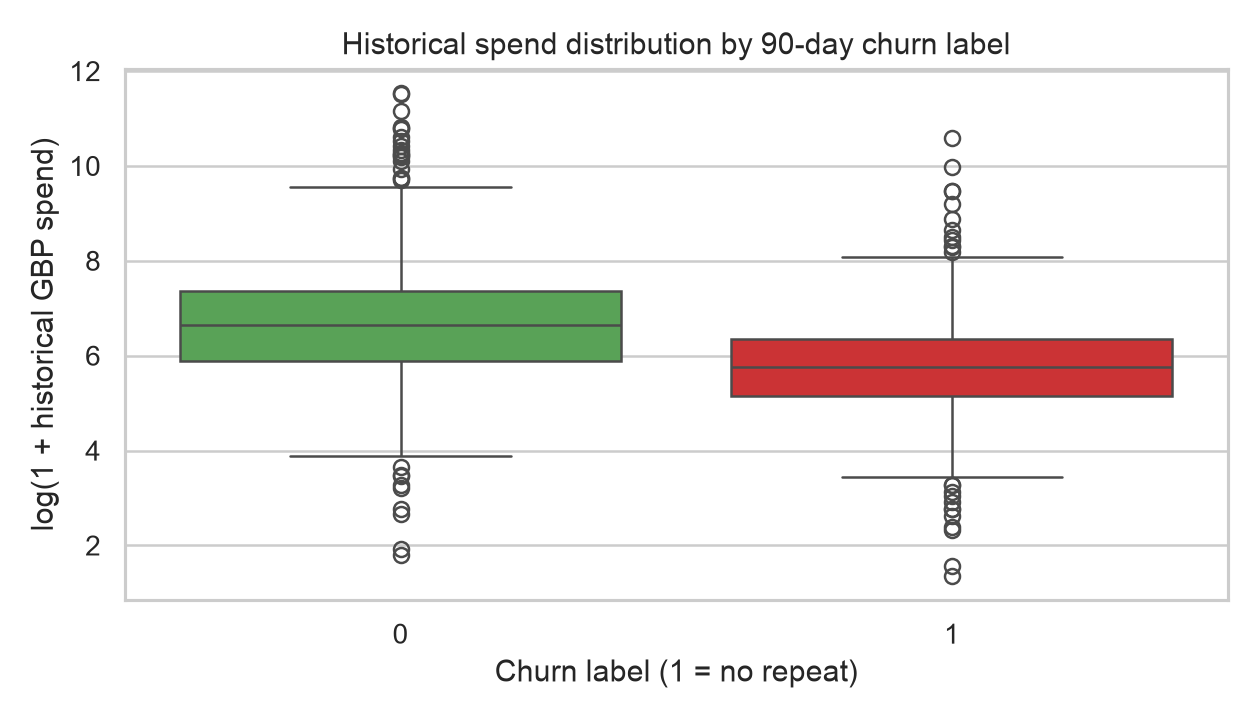

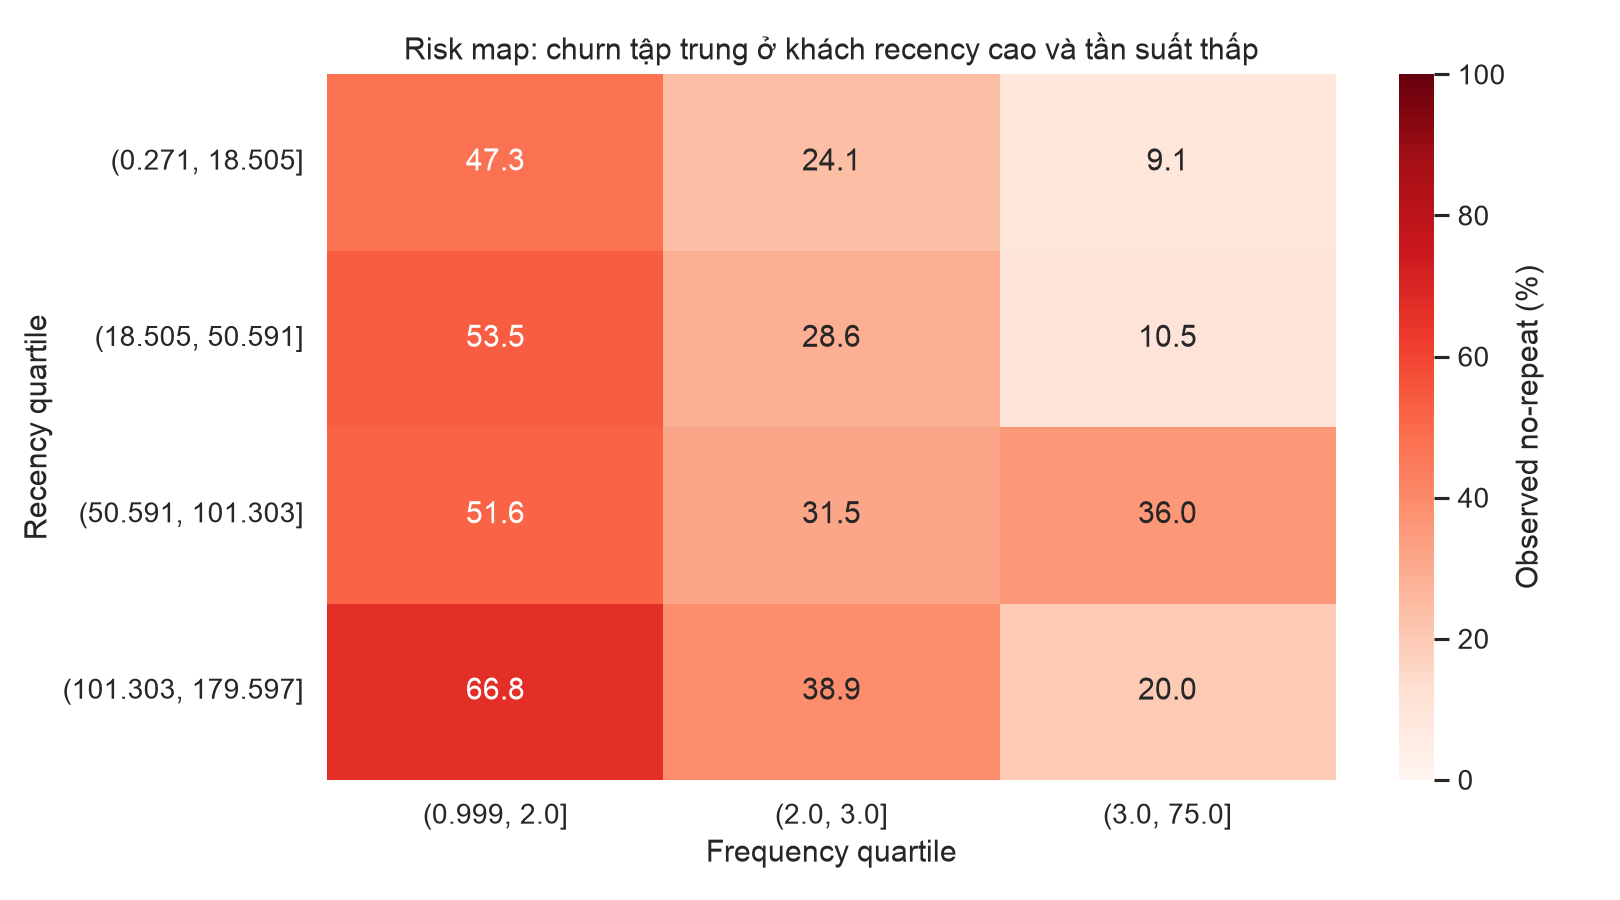

In [5]:
# Load snapshot test để bảo đảm biểu đồ chỉ dùng đúng population đánh giá.
snapshots = pd.read_parquet(PROC/'uci_snapshots.parquet')
test = snapshots.query("split == 'test'").copy()
display(Image(filename=str(FIG/'02_recency_churn.png')))
display(Image(filename=str(FIG/'06_spend_boxplot.png')))
display(Image(filename=str(FIG/'09_rfm_risk_heatmap.png')))

💡 **Giải thích trực quan cho người đọc:**
1. **Phân phối số ngày chưa mua - Recency (Hình trên cùng):**
   - Nhóm không mua lại (màu đỏ) lệch hẳn về bên phải: Đa số đã không mua hàng trên 60–100 ngày. Ngược lại, nhóm tiếp tục mua (màu xanh) tập trung ở các mốc thời gian gần (dưới 30 ngày).
2. **Phân phối mức chi tiêu - Spend Boxplot (Hình giữa):**
   - Cả hai nhóm khách đều có người chi nhiều và người chi ít. Chi tiêu quá khứ có độ phân tán cực kỳ rộng nên không thể nhìn đơn thuần vào số tiền đã tiêu để kết luận khách có bỏ đi hay không.
3. **Ma trận rủi ro RFM 2 chiều (Hình dưới cùng):**
   - Tỷ lệ rời bỏ vọt lên **trên 75% - 85%** ở những khách hàng có `Recency > 90 ngày`, bất kể trong quá khứ họ từng mua nhiều lần hay ít lần. Khách từng mua nhiều lần nhưng đột ngột ngưng mua chính là nhóm rủi ro nguy hiểm nhất.

## 6. Thiết kế nhãn Churn và Chia dữ liệu theo thời gian (Temporal Split)
Để mô phỏng đúng đời thực, ta chia dữ liệu thành 3 mốc thời gian nối tiếp nhau:
- **Tập Train (Huấn luyện):** Mốc cắt 30/01/2011 (Dùng 180 ngày trước đó để học hành vi, dự báo 90 ngày sau đó).
- **Tập Validation (Thẩm định):** Mốc cắt 30/04/2011 (Dùng để chọn ra thuật toán tốt nhất và hiệu chuẩn xác suất).
- **Tập Test (Kiểm thử độc lập):** Mốc cắt 30/07/2011 (Hoàn toàn nguyên vẹn, chỉ dùng để đánh giá điểm số cuối cùng).

In [6]:
# Báo cáo population và prevalence theo split; đây là kiểm tra denominator trước khi huấn luyện.
split_stats = snapshots.groupby('split', as_index=False).agg(
    So_khach_hang=('customer','nunique'),
    Ty_le_roi_bo_prevalence=('churn','mean'),
    Ngay_snapshot=('snapshot_date','first')
).sort_values('Ngay_snapshot')
split_stats['Ty_le_roi_bo_prevalence'] = split_stats['Ty_le_roi_bo_prevalence'].map('{:.1%}'.format)
split_stats.rename(columns={'split':'Tập dữ liệu', 'So_khach_hang':'Số khách hàng', 'Ty_le_roi_bo_prevalence':'Tỷ lệ Churn nền', 'Ngay_snapshot':'Ngày mốc snapshot'})

,Tập dữ liệu,Số khách hàng,Tỷ lệ Churn nền,Ngày mốc snapshot
1,train,3364,60.0%,2011-01-30
2,validation,3060,52.4%,2011-04-30
0,test,2788,44.3%,2011-07-30


## 7. Xây dựng đặc trưng hành vi (Feature Engineering)
Từ lịch sử giao dịch 180 ngày trước mốc cắt, trích xuất 7 đặc trưng hành vi:
1. `recency_days`: Số ngày kể từ lần mua gần nhất đến mốc đánh giá.
2. `frequency`: Tổng số đơn hàng đã đặt trong 180 ngày.
3. `monetary_log`: Tổng tiền chi tiêu (đã lấy log để chuẩn hóa).
4. `aov_log`: Giá trị trung bình của một đơn hàng (Average Order Value).
5. `product_diversity`: Số lượng mã sản phẩm khác nhau đã mua.
6. `interpurchase_mean`: Khoảng cách trung bình giữa các lần mua hàng.
7. `tenure_days`: Thâm niên gắn bó của khách hàng tính từ đơn đầu tiên.

In [7]:
# Kiểm tra completeness của feature set và xác nhận nhãn không bị dùng làm feature.
features = summary['selected_features']
pd.DataFrame({
    'Đặc trưng được chọn cho mô hình': features,
    'Tỷ lệ dữ liệu khuyết thiếu (Missing rate)': [f"{test[x].isna().mean():.1%}" for x in features]
})

,Đặc trưng được chọn cho mô hình,Tỷ lệ dữ liệu khuyết thiếu (Missing rate)
0,recency_days,0.0%
1,frequency,0.0%
2,monetary_log,0.0%


## 8. Lớp phân tích dự báo (Predictive Analytics): Huấn luyện và So sánh mô hình
So sánh 3 mô hình trên tập Validation:
1. **RFM Logistic Regression (Baseline):** Mô hình hồi quy cổ điển chỉ dùng 3 biến RFM.
2. **Full Logistic Regression:** Mô hình hồi quy dùng toàn bộ 7 biến hành vi mở rộng.
3. **HistGradientBoosting:** Mô hình cây quyết định tăng cường hiện đại có khả năng học các tương tác phi tuyến tính phức tạp.

*Mô hình có PR-AUC cao nhất trên tập Validation sẽ được chọn, sau đó áp dụng Platt Scaling (Sigmoid Calibration) để biến điểm số dự báo thành xác suất chuẩn xác.*

In [8]:
# Bảng so sánh mô hình được tạo từ output của pipeline, không tính lại trên test để chọn model.
metrics = pd.read_csv(OUT/'model_metrics.csv')
metrics_display = metrics.copy()
metrics_display['model'] = metrics_display['model'].replace({
    'RFM Logistic Regression': 'RFM Logistic Regression (Baseline)',
    'Logistic Regression': 'Full Logistic Regression',
    'HistGradientBoosting': 'HistGradientBoosting Classifier',
    'Selected uncalibrated': 'Selected Raw (Chưa hiệu chuẩn)',
    'Selected calibrated': 'Selected Calibrated (Đã hiệu chuẩn)'
})
metrics_display.style.format({
    'churn_prevalence': '{:.1%}',
    'roc_auc': '{:.3f}',
    'pr_auc': '{:.3f}',
    'brier': '{:.3f}',
    'brier_baseline': '{:.3f}',
    'brier_skill_score': '{:.1%}',
    'precision_at_10': '{:.1%}',
    'recall_at_10': '{:.1%}',
    'lift_at_10': '{:.2f}x'
})

,dataset,model,feature_set,n,churn_prevalence,roc_auc,pr_auc,brier,brier_baseline,brier_skill_score,precision_at_10,recall_at_10,lift_at_10
0,UCI validation,RFM Logistic Regression (Baseline),recency_days+frequency+monetary_log,3060,52.4%,0.750,0.728,0.201,0.249,19.6%,79.4%,15.2%,1.52x
1,UCI validation,Full Logistic Regression,recency_days+frequency+monetary_log+aov_log+product_diversity+interpurchase_mean+tenure_days,3060,52.4%,0.746,0.723,0.203,0.249,18.6%,79.1%,15.1%,1.51x
2,UCI validation,HistGradientBoosting Classifier,recency_days+frequency+monetary_log+aov_log+product_diversity+interpurchase_mean+tenure_days,3060,52.4%,0.708,0.686,0.226,0.249,9.6%,74.5%,14.2%,1.42x
3,UCI test,Selected Raw (Chưa hiệu chuẩn),recency_days+frequency+monetary_log,2788,44.3%,0.752,0.665,0.208,0.247,15.8%,71.7%,16.2%,1.62x
4,UCI test,Selected Calibrated (Đã hiệu chuẩn),recency_days+frequency+monetary_log,2788,44.3%,0.752,0.665,0.205,0.247,16.9%,71.7%,16.2%,1.62x


💡 **Giải thích trực quan cho người đọc:**
- **Vì sao mô hình đơn giản RFM Logistic Regression lại chiến thắng?**
  Trên tập Validation, RFM Logistic Regression đạt **PR-AUC = 0.728**, cao hơn cả Full Logistic Regression (0.723) và HistGradientBoosting (0.686). Điều này tuân theo nguyên lý kinh điển trong khoa học dữ liệu (*Dao cạo Occam*): Mô hình đơn giản hơn thường ít bị nhiễu, hoạt động ổn định và dễ giải thích cho ban giám đốc hơn.
- **Brier Skill Score (BSS):** Đo độ chính xác của xác suất so với đoán tỷ lệ nền. BSS của mô hình RFM chưa hiệu chuẩn đạt **19.6%** trên Validation, là tín hiệu chọn mô hình tốt hơn baseline. Platt calibration được fit sau đó trên Validation; hiệu quả hiệu chuẩn chỉ được báo cáo trên Test untouched.

## 9. Đánh giá cuối cùng trên tập Test độc lập (Final Evaluation)
Khóa toàn bộ tham số mô hình và chạy kiểm tra một lần duy nhất trên **2,788 khách hàng** thuộc tập Test chưa từng được nhìn thấy trước đó.

In [9]:
# Chỉ đọc kết quả untouched test đã khóa trong pipeline.
final_test = metrics[(metrics.dataset=='UCI test') & (metrics.model=='Selected calibrated')]
ci = pd.read_csv(OUT/'uci_test_bootstrap_ci.csv')

print("=== KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST ĐỘC LẬP ===")
display(final_test[['model', 'n', 'churn_prevalence', 'roc_auc', 'pr_auc', 'brier_skill_score', 'precision_at_10', 'lift_at_10']].style.format({
    'churn_prevalence': '{:.1%}',
    'roc_auc': '{:.3f}',
    'pr_auc': '{:.3f}',
    'brier_skill_score': '{:.1%}',
    'precision_at_10': '{:.1%}',
    'lift_at_10': '{:.2f}x'
}))

print("=== KHOẢNG TIN CẬY 95% BOOTSTRAP (1,000 LẦN LẤY MẪU) ===")
display(ci.style.format({'estimate':'{:.3f}','ci_95_low':'{:.3f}','ci_95_high':'{:.3f}'}))

=== KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST ĐỘC LẬP ===


,model,n,churn_prevalence,roc_auc,pr_auc,brier_skill_score,precision_at_10,lift_at_10
4,Selected calibrated,2788,44.3%,0.752,0.665,16.9%,71.7%,1.62x


=== KHOẢNG TIN CẬY 95% BOOTSTRAP (1,000 LẦN LẤY MẪU) ===


,metric,estimate,ci_95_low,ci_95_high,n_bootstrap
0,roc_auc,0.752,0.733,0.769,1000
1,pr_auc,0.665,0.636,0.697,1000
2,precision_at_10,0.717,0.667,0.774,1000


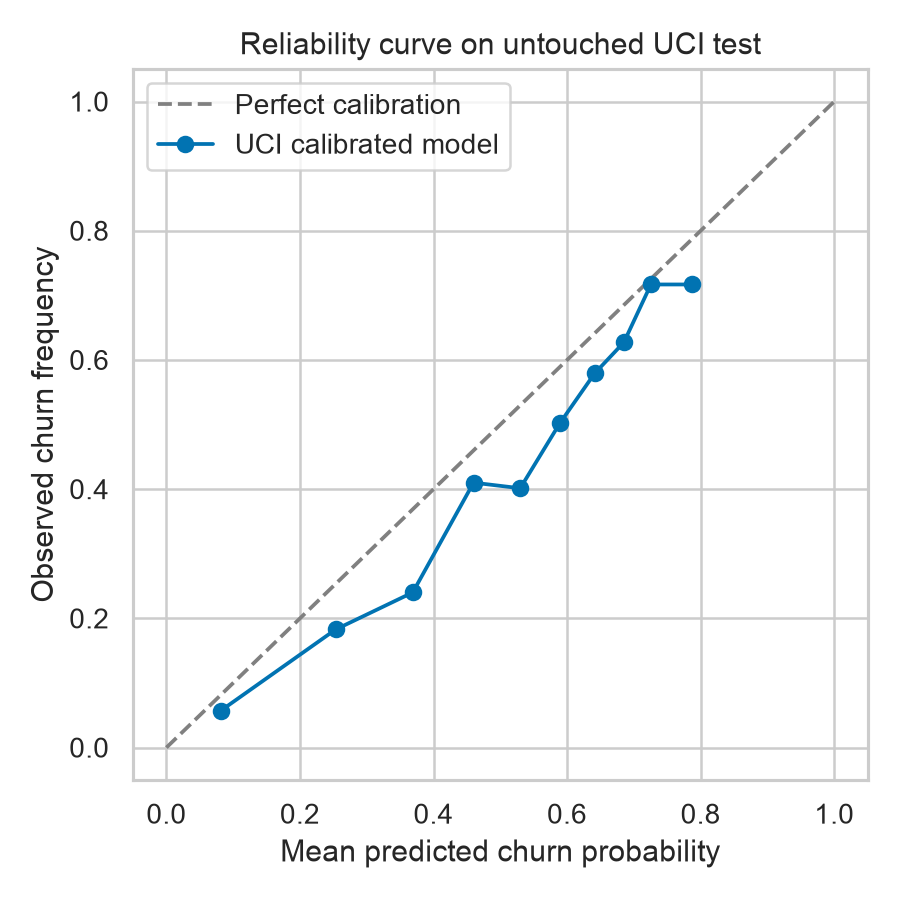

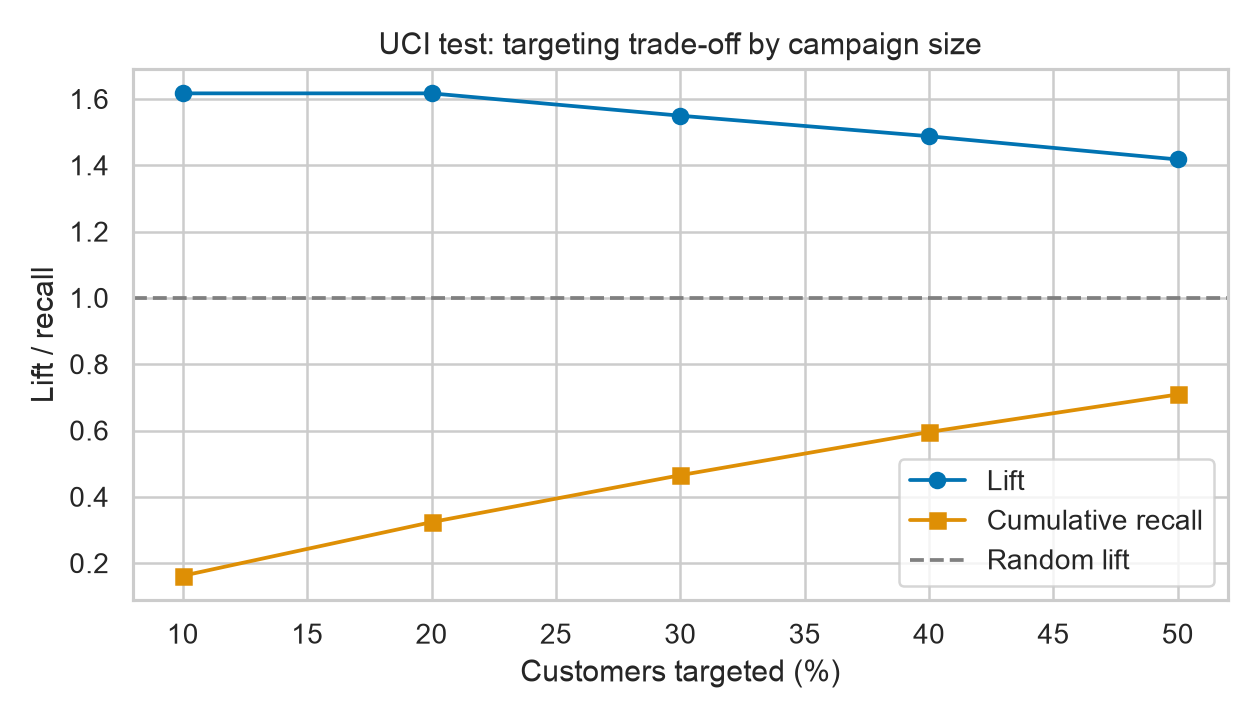

In [10]:
# Calibration và lift/gain là hai kiểm tra bổ sung cho quyết định target.
display(Image(filename=str(FIG/'04_calibration.png')))
display(Image(filename=str(FIG/'07_gains_lift.png')))

💡 **Giải thích trực quan các chỉ số kiểm thử:**
1. **ROC-AUC = 0.752 (95% CI: 0.733 – 0.769):**
   - Khả năng mô hình xếp người sắp bỏ đi lên trước người ở lại đạt 75.2%. Trong bài toán khách hàng thương mại điện tử không hợp đồng, mức 0.75 là điểm số vững chắc và thực tế. Khoảng tin cậy hẹp chứng minh kết quả không phải do ăn may.
2. **Precision@10% = 71.7% và Lift@10% = 1.62x:**
   - Nếu bốc ngẫu nhiên khách hàng để gửi voucher, tỷ lệ trúng khách sắp bỏ đi chỉ là 44.3% (tỷ lệ nền).
   - Nhưng nếu dùng mô hình chọn **top 10% rủi ro nhất (279 khách)**, tỷ lệ bắt trúng vọt lên **71.7%** — gấp **1.62 lần** so với ngẫu nhiên!
3. **Đường cong hiệu chuẩn Reliability Curve (Hình 4):**
   - Đường thực tế nhìn chung bám theo xu hướng đường chéo nhưng vẫn có sai lệch ở một số bins, nhất là vùng xác suất thấp và rất cao. Vì vậy, xác suất dự báo phù hợp để xếp hạng và ước lượng thận trọng, không được diễn giải như một xác suất chính xác tuyệt đối cho từng khách hàng.

## 10. Phân tích đánh đổi quy mô chiến dịch qua Bảng Gains & Lift
Nếu chỉ chọn top 10% thì bỏ sót nhiều khách. Nếu chọn top 50% thì ngân sách có kham nổi không? Bảng Gains dưới đây giúp Giám đốc Marketing cân nhắc bài toán kinh tế.

In [11]:
# Đọc và hiển thị bảng Gains chi tiết theo quy mô chiến dịch
gains = pd.read_csv(OUT/'uci_test_gains_table.csv')
gains_display = gains.copy()
gains_display.columns = ['Tỷ lệ khách target', 'Số lượng khách can thiệp', 'Độ chính xác (Precision)', 'Độ phủ bắt trúng (Recall)', 'Hệ số đòn bẩy (Lift)']
gains_display.style.format({
    'Tỷ lệ khách target': '{:.0%}',
    'Độ chính xác (Precision)': '{:.1%}',
    'Độ phủ bắt trúng (Recall)': '{:.1%}',
    'Hệ số đòn bẩy (Lift)': '{:.2f}x'
})

,Tỷ lệ khách target,Số lượng khách can thiệp,Độ chính xác (Precision),Độ phủ bắt trúng (Recall),Hệ số đòn bẩy (Lift)
0,10%,279,71.7%,16.2%,1.62x
1,20%,558,71.7%,32.4%,1.62x
2,30%,837,68.7%,46.5%,1.55x
3,40%,1116,65.9%,59.5%,1.49x
4,50%,1394,62.8%,70.9%,1.42x


💡 **Giải thích trực quan bảng Gains (Quyết định ngân sách):**
- **Chọn Top 10% (279 khách):** Đạt độ chính xác cao nhất (71.7%), bắt được 16.2% tổng lượng khách rời bỏ. Phù hợp cho chiến dịch thử nghiệm ngân sách nhỏ.
- **Chọn Top 20% (558 khách):** Điều kỳ diệu là độ chính xác **vẫn giữ nguyên 71.7%**, đòn bẩy vẫn là 1.62x, nhưng bắt được gấp đôi lượng khách rời bỏ (**32.4%**).
- **Chọn Top 30% (837 khách):** Độ chính xác vẫn rất cao (**68.7%**) và tóm được **gần một nửa (46.5%)** toàn bộ khách hàng sắp rời bỏ trên sàn.
- 👉 **Điểm ngọt tối ưu:** Ban giám đốc nên ưu tiên chạy chiến dịch ở ngưỡng **top 20% - 30%** để tối đa hóa lượng khách giữ chân được mà không bị lãng phí chi phí marketing.

## 11. Diễn giải mô hình (Model Interpretability) & Kiểm tra độ nhạy
Mô hình hồi quy Logistic cho phép ta nhìn thấu cơ chế ra quyết định thông qua Hệ số chuẩn hóa và Tỷ số chênh (Odds Ratio).

In [12]:
# Hiển thị trọng số các biến và bảng kiểm tra độ nhạy theo cửa sổ thời gian
coefficients = pd.read_csv(OUT/'uci_logistic_coefficients.csv')
sensitivity = pd.read_csv(OUT/'uci_horizon_sensitivity.csv')

print("=== TRỌNG SỐ VÀ TỶ SỐ CHÊNH CỦA CÁC BIẾN ===")
display(coefficients.rename(columns={'feature':'Đặc trưng', 'standardized_coefficient':'Hệ số chuẩn hóa', 'odds_ratio_per_1sd':'Tỷ số chênh (OR/1SD)'}).style.format({
    'Hệ số chuẩn hóa': '{:.3f}',
    'Tỷ số chênh (OR/1SD)': '{:.2f}'
}))

print("=== KIỂM TRA ĐỘ NHẠY VỚI CÁC CỬA SỔ CHURN 60, 90, 120 NGÀY ===")
display(sensitivity[['horizon_days', 'churn_prevalence', 'roc_auc', 'pr_auc', 'brier_skill_score', 'lift_at_10']].rename(columns={
    'horizon_days': 'Cửa sổ (Ngày)', 'churn_prevalence':'Tỷ lệ Churn nền', 'brier_skill_score':'BSS'
}).style.format({
    'Tỷ lệ Churn nền': '{:.1%}',
    'roc_auc': '{:.3f}',
    'pr_auc': '{:.3f}',
    'BSS': '{:.1%}',
    'lift_at_10': '{:.2f}x'
}))

=== TRỌNG SỐ VÀ TỶ SỐ CHÊNH CỦA CÁC BIẾN ===


,Đặc trưng,Hệ số chuẩn hóa,Tỷ số chênh (OR/1SD)
0,frequency,-1.306,0.27
1,monetary_log,-0.390,0.68
2,recency_days,0.198,1.22


=== KIỂM TRA ĐỘ NHẠY VỚI CÁC CỬA SỔ CHURN 60, 90, 120 NGÀY ===


,Cửa sổ (Ngày),Tỷ lệ Churn nền,roc_auc,pr_auc,BSS,lift_at_10
0,60,57.3%,0.749,0.772,18.1%,1.45x
1,90,44.3%,0.752,0.665,16.9%,1.62x
2,120,36.4%,0.753,0.585,7.7%,1.77x


💡 **Giải thích trực quan các con số trên:**
1. **Frequency (Tần suất mua) là lá chắn mạnh nhất:**
   - Hệ số âm lớn nhất (-1.306), Tỷ số chênh (Odds Ratio) = **0.27**.
   - *Ý nghĩa đời thường:* Khách hàng cứ tăng 1 độ lệch chuẩn về số lần mua sắm trong quá khứ thì nguy cơ bỏ đi giảm tới **73%** (1 - 0.27). Khách mua thường xuyên chính là tài sản quý giá nhất.
2. **Recency (Số ngày chưa mua) là hồi chuông cảnh báo:**
   - Hệ số dương (+0.198), Odds Ratio = **1.22**.
   - Cứ mỗi một khoảng thời gian dài ra mà khách không quay lại, nguy cơ họ bỏ đi vĩnh viễn tăng thêm **22%**.
3. **Kiểm tra độ nhạy cửa sổ thời gian (60 vs 90 vs 120 ngày):**
   - Dù ta định nghĩa rời bỏ là 60 ngày, 90 ngày hay 120 ngày, ROC-AUC của mô hình duy trì trong khoảng **0.749 – 0.753**. Đây là kiểm tra độ bền trong cùng dữ liệu UCI, không phải bằng chứng khái quát hóa sang thị trường hay thời kỳ khác.

## 12. Lớp phân tích chỉ định (Prescriptive Analytics): Kết hợp Rủi Ro và Giá Trị CLV 90 ngày
Biết ai sắp bỏ đi mới chỉ là 50% câu chuyện. 50% còn lại là: **Khách đó có đáng để bỏ tiền giữ chân hay không?**
- Áp dụng mô hình kinh tế lượng **BG/NBD** (dự báo số lần mua kỳ vọng) và **Gamma-Gamma** (dự báo giá trị đơn hàng kỳ vọng) để tính ra **CLV 90 ngày** (Customer Lifetime Value) tính bằng tiền bảng Anh (GBP).

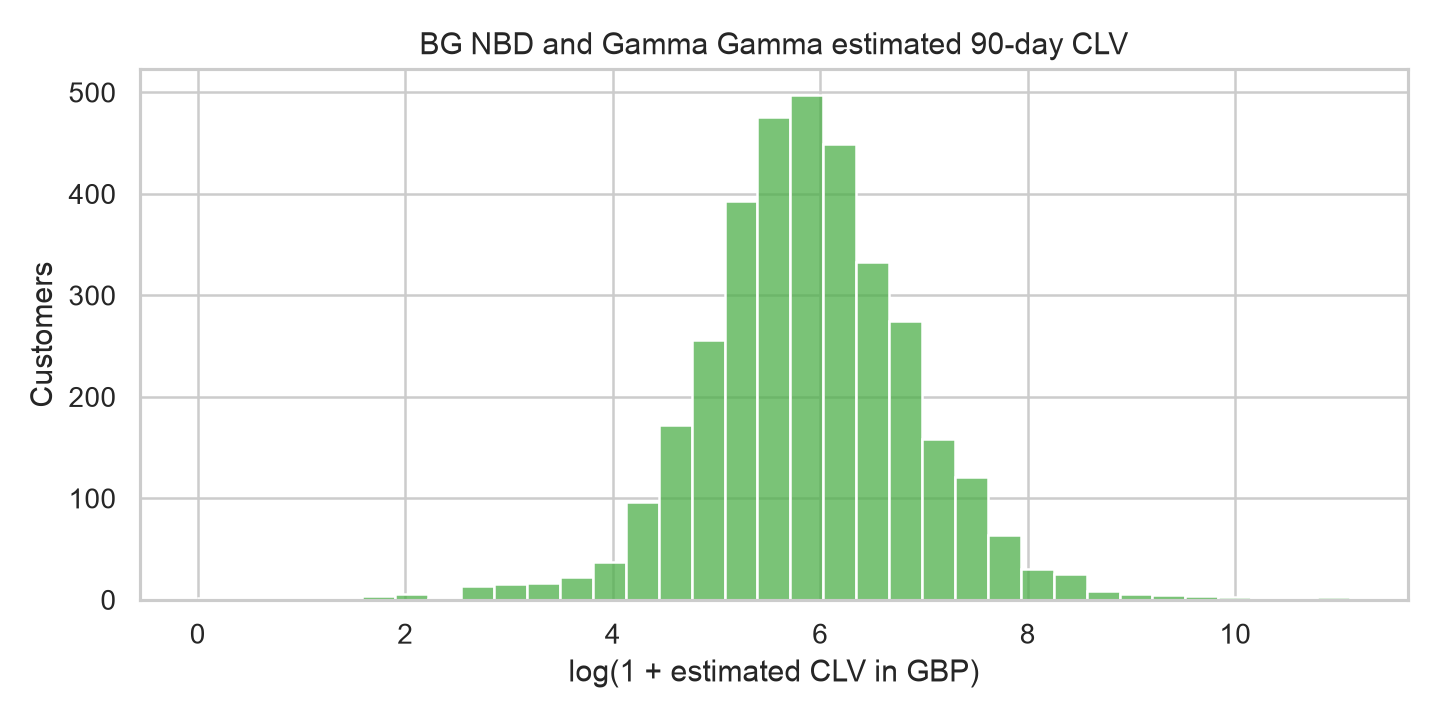

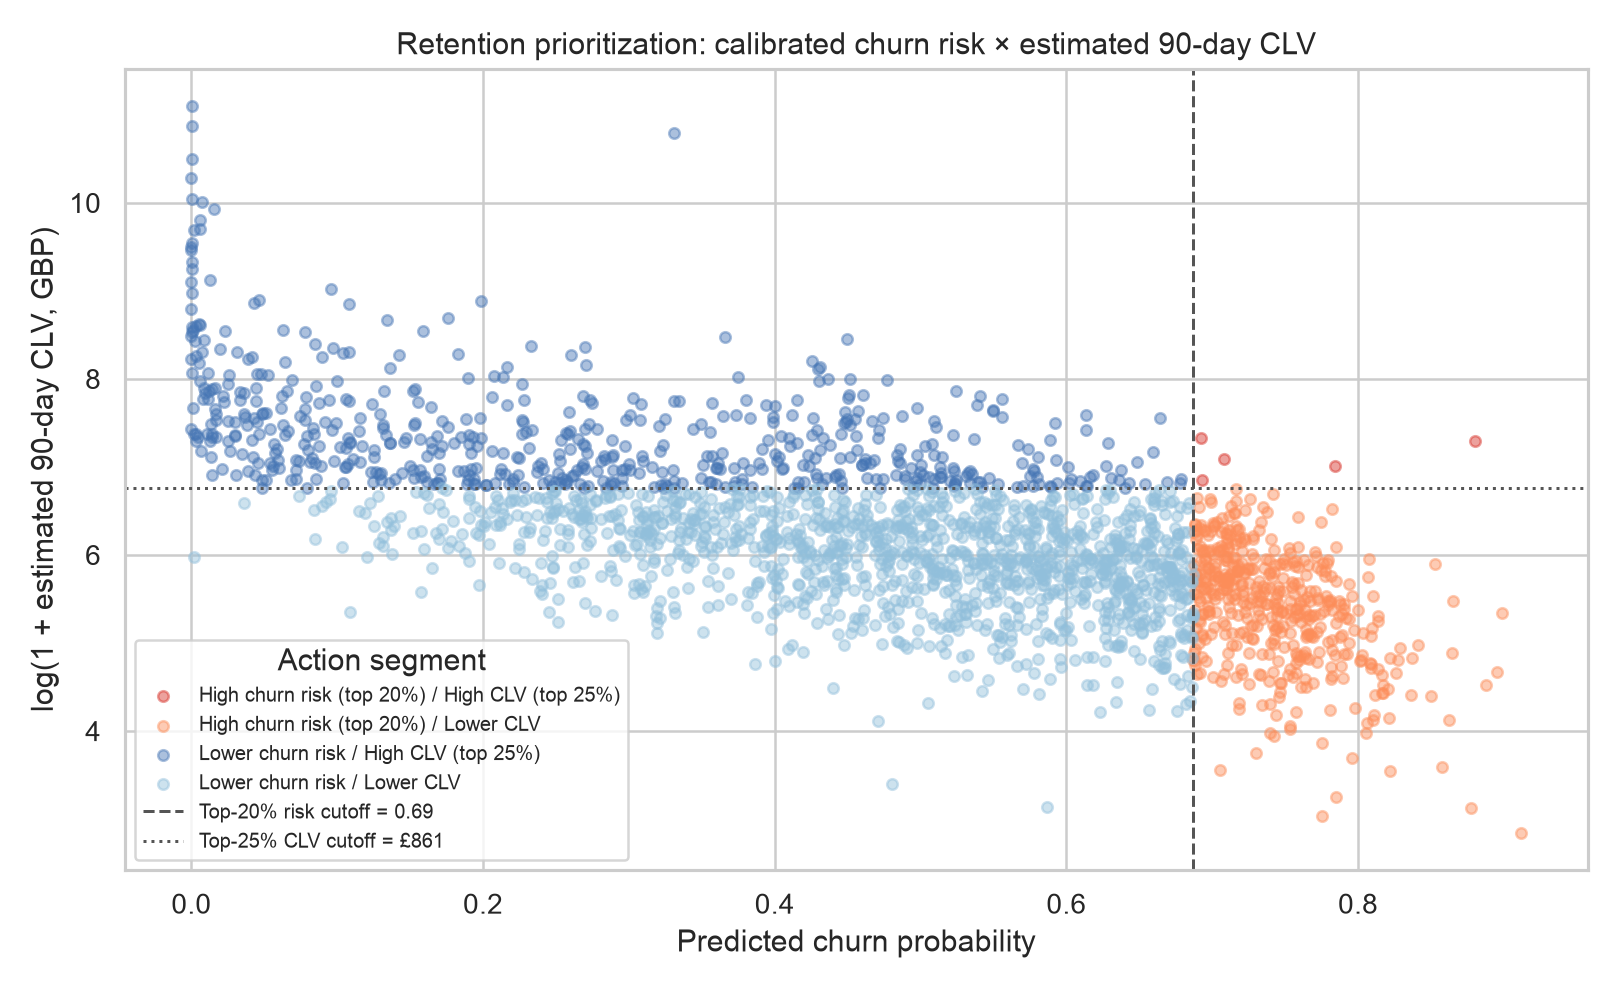

,customers_with_clv,risk_cut_top20,clv_cut_top25,high_risk_high_clv_customers,high_risk_low_clv_customers
0,2337,0.687,£861,5,463


,priority_segment,customers,observed_churn,mean_clv_90d
0,High churn risk (top 20%) / High CLV (top 25%),5,100.0%,"£1,255"
1,High churn risk (top 20%) / Lower CLV,463,63.3%,£267
2,Lower churn risk / High CLV (top 25%),580,18.1%,"£2,428"
3,Lower churn risk / Lower CLV,1289,39.6%,£432


In [13]:
# Trực quan hóa phân phối CLV và ma trận ưu tiên dùng đúng xác suất churn đã hiệu chuẩn.
thresholds = pd.read_csv(OUT/'prescriptive_thresholds.csv')
segments = pd.read_csv(OUT/'prescriptive_segments.csv')
display(Image(filename=str(FIG/'05_clv_distribution.png')))
display(Image(filename=str(FIG/'10_risk_clv_priority.png')))
display(thresholds.style.format({'risk_cut_top20':'{:.3f}', 'clv_cut_top25':'£{:,.0f}'}))
display(segments.style.format({'observed_churn':'{:.1%}', 'mean_clv_90d':'£{:,.0f}'}))

💡 **Giải thích ma trận ưu tiên (Hình 10):**
Hình dùng **xác suất churn đã hiệu chuẩn** trên trục ngang và **CLV 90 ngày ước lượng** trên trục dọc; đường dọc là ngưỡng top 20% risk, còn đường ngang là top 25% CLV. Vì vậy, bốn vùng là các phân đoạn quyết định có thể kiểm chứng từ bảng ngay bên dưới hình:
1. **High risk - High CLV:** Chỉ ưu tiên voucher/CSKH chi phí cao cho nhóm giao nhau này; không giả định nhóm có quy mô lớn nếu bảng cho thấy ít khách.
2. **High risk - Lower CLV:** Dùng email/push cá nhân hóa và theo dõi hiệu quả, vì đây là nhóm rủi ro nhưng giá trị dự báo thấp hơn.
3. **Lower risk - High CLV:** Ưu tiên loyalty nhẹ hoặc trải nghiệm; không tự động cấp voucher chỉ vì giá trị cao.
4. **Lower risk - Lower CLV:** Không ưu tiên ngân sách giữ chân trực tiếp. Mọi quyết định chi ưu đãi vẫn cần kiểm chứng bằng A/B test.

## 13. Benchmark thuật toán phụ trợ trên tập KKBox (709,200 khách hàng)
Đây là benchmark có nhãn trên feature matrix công khai đã tiền xử lý của bài toán KKBox (WSDM Cup). Vì matrix không còn timestamp gốc, phép chia là stratified hold-out; nó chỉ giúp so sánh thuật toán trong chính benchmark này, không xác nhận khả năng triển khai UCI sang một ngành khác.

In [14]:
# Đọc và hiển thị kết quả benchmark trên KKBox
kkbox = pd.read_csv(OUT/'kkbox_benchmark_metrics.csv')
kkbox.style.format({
    'churn_prevalence': '{:.1%}',
    'roc_auc':'{:.3f}',
    'pr_auc':'{:.3f}',
    'brier':'{:.3f}',
    'brier_baseline':'{:.3f}',
    'brier_skill_score':'{:.1%}',
    'precision_at_10':'{:.1%}',
    'recall_at_10':'{:.1%}',
    'lift_at_10':'{:.2f}x'
})

,dataset,model,n_test,churn_prevalence,roc_auc,pr_auc,brier,brier_baseline,brier_skill_score,precision_at_10,recall_at_10,lift_at_10
0,KKBox labelled benchmark,Logistic Regression baseline,88650,4.9%,0.855,0.356,0.037,0.046,21.1%,31.5%,64.6%,6.46x
1,KKBox labelled benchmark,HistGradientBoosting,88650,4.9%,0.878,0.420,0.035,0.046,24.7%,32.7%,67.1%,6.71x


💡 **Giải thích kết quả Benchmark:**
- Trên benchmark KKBox, **HistGradientBoosting** đạt ROC-AUC = **0.878**, PR-AUC = **0.420** và Lift@10% = **6.71x**, cao hơn Logistic Regression về ROC-AUC (0.855) và Lift (6.46x).
- Kết quả này là bằng chứng so sánh thuật toán trên feature matrix KKBox, **không** là external validation, temporal validation hay bằng chứng hiệu năng triển khai cho case UCI. Không so sánh trực tiếp PR-AUC giữa hai bộ dữ liệu vì prevalence và hành vi khách hàng khác nhau.

## 14. Khuyến nghị hỗ trợ quyết định & Thiết kế thử nghiệm A/B Testing
Đề xuất dưới đây truy ngược rõ ràng về ba lớp phân tích trước: (i) cohort cho thấy chỉ **15–25%** khách quay lại ở tháng thứ hai, (ii) diagnostic heatmap cho thấy nhóm recency trên 90 ngày có churn quan sát **75–85%**, và (iii) mô hình trên UCI test đạt Precision **68.7–71.7%** cùng Recall **32–46%** khi target top 20–30%.

### Kế hoạch hành động 4 bước tối ưu ngân sách:
1. **Quy mô campaign:** Chạy pilot trên **top 20%** trước (558/2,788 khách trong test): Precision **71.7%**, Recall **32.4%**, Lift **1.62x**. Chỉ mở rộng tới top 30% khi ngân sách cho phép, vì Precision giảm còn **68.7%** dù Recall tăng lên **46.5%**.
2. **Phân bổ theo risk × CLV:** Trong nhóm có CLV ước lượng, dùng đúng hai ngưỡng hiển thị ở Hình 10/bảng kèm theo: top 20% churn risk và top 25% CLV. Chỉ phân nhóm giao nhau để thử voucher/CSKH chi phí cao; nhóm high-risk nhưng lower-CLV nhận email/push chi phí thấp. Đây là quy tắc ưu tiên ngân sách, không phải ước lượng lợi nhuận thực vì UCI không có margin.
3. **Không gửi voucher đại trà cho nhóm lower-risk:** Giữ nhóm này làm đối tượng quan sát/đối chứng hoặc chỉ dùng loyalty nhẹ. Quyết định này giảm nguy cơ chi ưu đãi cho khách vốn có khả năng quay lại, nhưng chưa khẳng định được mức tiết kiệm hay tác động nhân quả.
4. **Thiết kế thử nghiệm A/B Testing có đối chứng (Causal Uplift):**
   - Trước khi chi ngân sách toàn sàn, triển khai thử nghiệm trong 30 ngày cho 1,000 khách hàng thuộc diện ưu tiên.
   - **Nhóm Can thiệp (Treatment Group - 800 khách):** Nhận voucher giữ chân cá nhân hóa.
   - **Nhóm Đối chứng (Control Group - 200 khách):** Giữ nguyên, không nhận can thiệp gì.
   - **Đánh giá hiệu quả:** Đo lường tỷ lệ mua lại tăng thêm thực tế: `Uplift = Repeat Rate (Treatment) - Repeat Rate (Control)` và tính toán Lợi nhuận tăng thêm ròng (Incremental ROI) để quyết định phân bổ ngân sách quý tới.

## 15. Giới hạn nghiên cứu & Tính tái lập (Reproducibility)
- **Giới hạn dữ liệu:** Bộ dữ liệu UCI là bán sỉ/quà tặng tại Anh, không chứa dữ liệu biên lợi nhuận (cost/margin) cụ thể nên CLV là giá trị giao dịch ước tính.
- **Tính nhân quả:** Điểm số rủi ro của mô hình là dự báo thống kê; chỉ có thử nghiệm A/B test thực tế mới chứng minh được voucher có tạo ra tác động nhân quả giữ chân khách hay không.
- **Cách chạy lại toàn bộ hệ thống từ đầu:**
  ```bash
  python src/pipeline.py
  python src/kkbox_benchmark.py
  python src/extended_visuals.py
  python src/build_report.py
  python src/build_notebook.py
  streamlit run app/app.py
  ```